# Assignment 3 — graph-tool part (Question 1b, 1c)

This notebook needs the `cmns-graphtool` / graph-tool kernel. Questions 1(a), 1(d), 2, 3 and 4 are in `assignment03.ipynb`.

In [1]:
import graph_tool.all as gt
import numpy as np
import matplotlib.pyplot as plt

# Fix the random seeds so the results are reproducible
np.random.seed(42)
gt.seed_rng(42)


## Question 1(b)

In [2]:
# Load the polblogs network from Netzschleuder
g = gt.collection.ns["polblogs"]

# Keep only the largest connected component
g = gt.extract_largest_component(g, directed=False)
print(g.num_vertices(), "nodes,", g.num_edges(), "edges")

1222 nodes, 19089 edges


In [3]:
# Fit a degree-corrected SBM with exactly two blocks
state_dc = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=True), multilevel_mcmc_args=dict(B_min=2, B_max=2))

# Fit a non-degree-corrected SBM with exactly two blocks
state_ndc = gt.minimize_blockmodel_dl(g, state_args=dict(deg_corr=False), multilevel_mcmc_args=dict(B_min=2, B_max=2))

# Check that both partitions really have two blocks
print("DC blocks:", state_dc.get_nonempty_B(), "| NDC blocks:", state_ndc.get_nonempty_B())


DC blocks: 2 | NDC blocks: 2


In [4]:
# Compute one layout so both drawings place the nodes in the same spots
pos = gt.sfdp_layout(g)

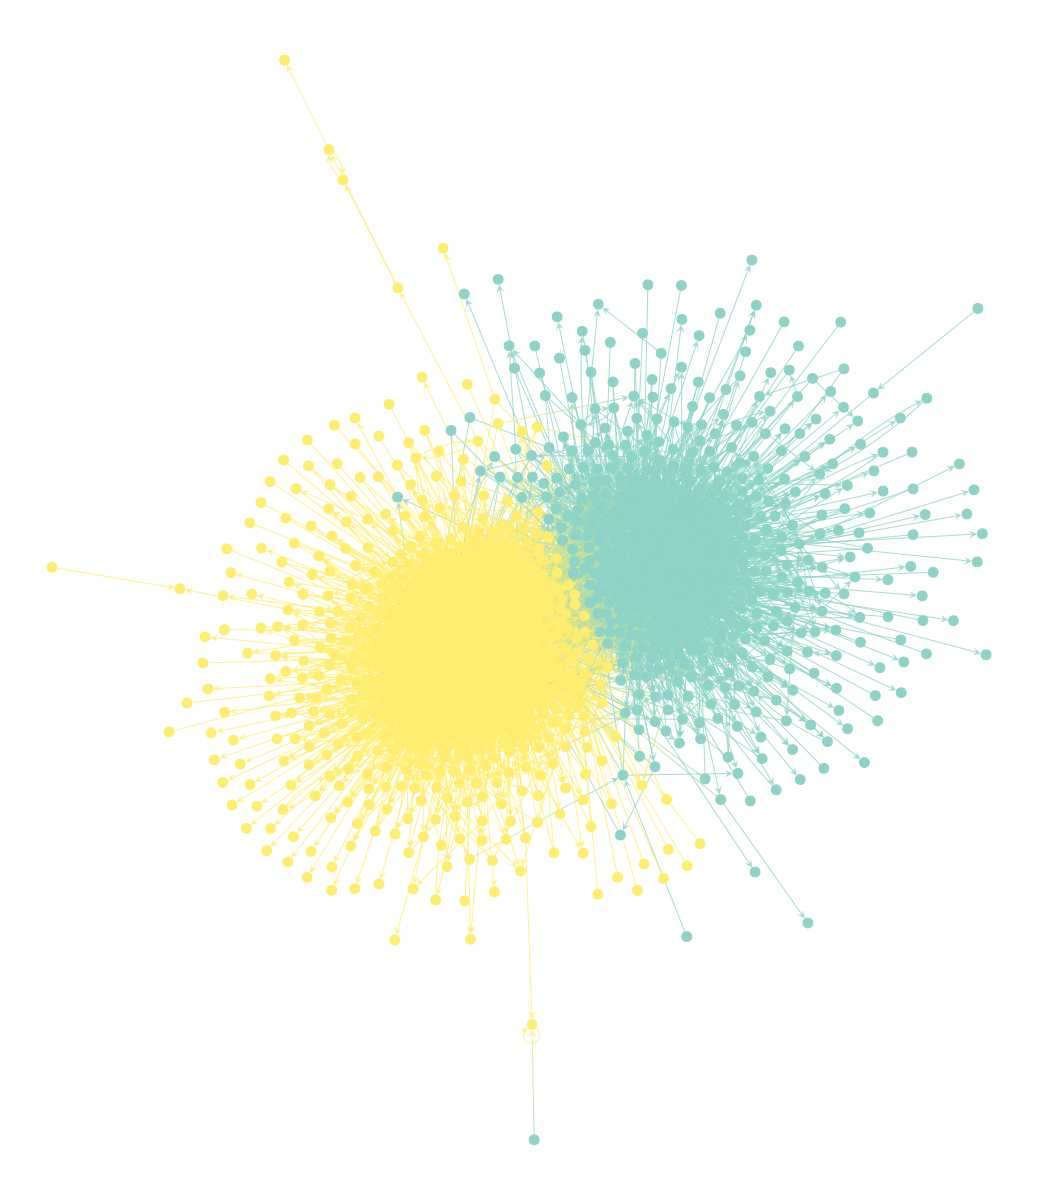

In [5]:
# Draw the graph colored by the degree-corrected partition
state_dc.draw(pos=pos, bg_color="white");


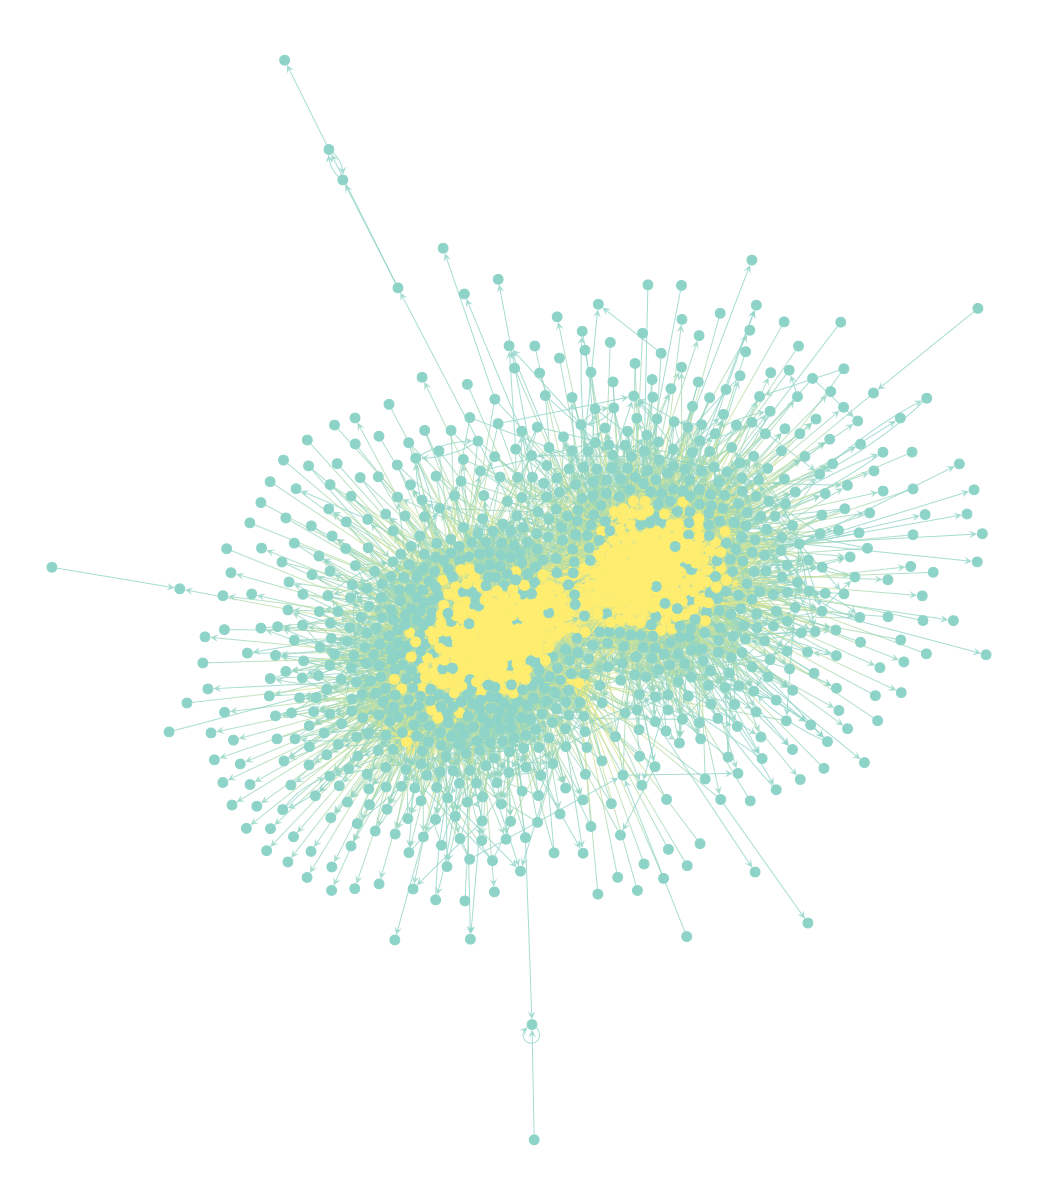

In [6]:
# Draw the graph colored by the non-degree-corrected partition
state_ndc.draw(pos=pos, bg_color="white");


The two partitions are very different. The **degree-corrected** SBM splits the network into two groups of blogs that link mostly among themselves: these correspond to the liberal/conservative division of polblogs. The **non-degree-corrected** SBM instead puts the most connected blogs in one small, dense group at the center and almost all other blogs in a second group around it. So without degree correction the two blocks separate nodes by their degree (core vs. periphery), not by their political side.

## Question 1(c.i)

In [7]:
# Description length of the two models from (b)
print("Degree-corrected:", state_dc.entropy())
print("Non-degree-corrected:", state_ndc.entropy())

Degree-corrected: 63429.747538188814
Non-degree-corrected: 83090.59283383832


## Question 1(c.ii)

In [8]:
# Random two-block starting partition
b = np.random.randint(0, 2, g.num_vertices())

# Two new models (both starting from the same random partition)
s_dc = gt.BlockState(g, b=b, deg_corr=True)
s_ndc = gt.BlockState(g, b=b, deg_corr=False)

# Run 1000 MCMC steps and save the description length at each step
dl_dc = []
dl_ndc = []
for i in range(1000):
    s_dc.mcmc_sweep(niter=1)
    s_ndc.mcmc_sweep(niter=1)
    dl_dc.append(s_dc.entropy())
    dl_ndc.append(s_ndc.entropy())

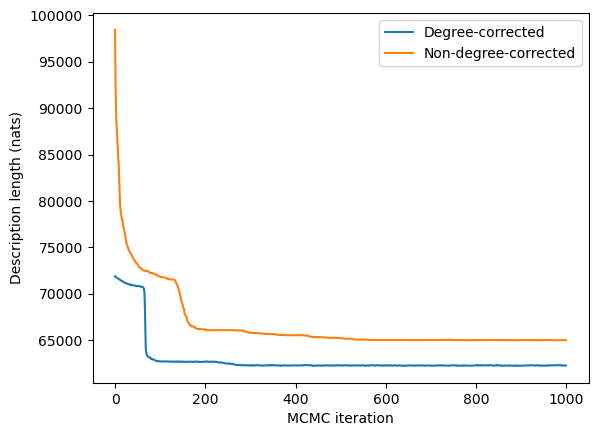

5 15


In [9]:
# Plot both curves
plt.plot(dl_dc, label="Degree-corrected")
plt.plot(dl_ndc, label="Non-degree-corrected")
plt.xlabel("MCMC iteration")
plt.ylabel("Description length (nats)")
plt.legend()
plt.show()

# Number of blocks at the end
print(s_dc.get_nonempty_B(), s_ndc.get_nonempty_B())

Both description lengths drop sharply in the first iterations, as the MCMC moves away from the random starting partition, and then level off with only small fluctuations. Both curves also show plateaus: the degree-corrected model stays around 71,000 for the first ~65 iterations before a sudden drop, and the non-degree-corrected model stays around 72,000 between roughly iterations 50 and 140 before dropping again. This shows that the MCMC can remain stuck in a local minimum for a while before finding a better partition.

At the end, the degree-corrected model reaches a lower description length (≈62,300 vs ≈65,000 nats), meaning it gives a better, more compressed description of the network. It also needs far fewer blocks: 5, against 15 for the non-degree-corrected model. This is expected for polblogs, which has very heterogeneous degrees: without degree correction, the model has to use extra blocks to explain differences in degree rather than real group structure.

Since the number of blocks was not fixed during the loop, both models end with more than two blocks, and both reach a lower description length than the two-block fits of (b) (63,430 for DC and 83,091 for NDC in c.i). This suggests that two blocks is not the best description of the network according to the MDL criterion, especially for the non-degree-corrected model.